# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : David Paskah
- NIM     : 241011402855
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =  55  # isi dengan 2 digit terakhir NIM Anda

In [69]:
# salin fungsi dari materi

# train_test_split
def train_test_split(X, y, test_size=0.25, random_state=None):
    X = np.asarray(X)
    y = np.asarray(y)

    if not 0 < test_size < 1:
        raise ValueError("test_size must be between 0 and 1")

    n_total = len(X)
    n_test = int(round(n_total * test_size))

    if random_state is not None:
        rng = np.random.RandomState(random_state)
        indices = rng.permutation(n_total)
    else:
        indices = np.random.permutation(n_total)

    test_idx = indices[:n_test]
    train_idx = indices[n_test:]

    X_train = X[train_idx]
    X_test = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    return X_train, X_test, y_train, y_test

# Linear Regression 
class LinearRegression:
    def __init__(self):
        self.intercept_ = 0.0
        self.coefficients_ = None

    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ y

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_
    
#Linear Regression GD

class LinearRegressionGD:
    def __init__(self, learning_rate=0.02, n_iterations=5000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coefficients_ = None
        self.loss_history_ = []
        self.beta_history_ = []

    # Training
    def fit(self, X, y):
        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]
        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):
            y_hat = X_b @ beta
            gradient = X_b.T @ (y_hat - y) / len(y)
            beta = beta - self.learning_rate * gradient

            loss = np.mean((y - X_b @ beta) ** 2)
            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]
        return self

    # Testing
    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return self.intercept_ + X @ self.coefficients_

    




---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3
jumlah baris data :  40


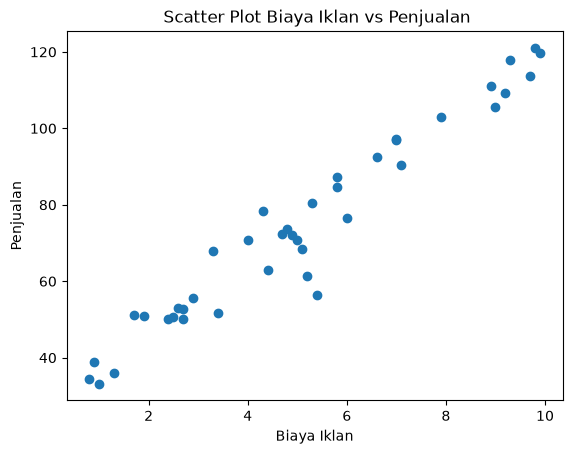

In [70]:
# Jawaban A1
import pandas as pd
import matplotlib.pyplot as plt

# 1
ads_data = pd.read_csv('Ads_Data.csv')

print(ads_data.head())
print("jumlah baris data : ", len(ads_data))


# 2
X_ads = ads_data[['BiayaIklan']]
y_ads = ads_data['Penjualan']

# 3
plt.scatter(X_ads, y_ads)
plt.title(' Scatter Plot Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan')
plt.ylabel('Penjualan')
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [71]:
# Jawaban A2

RANDOM_STATE = 55  # 2 digit terakhir NIM

X_train_ads, X_test_ads, y_train_ads, y_test_ads = train_test_split(
    X_ads,
    y_ads,
    test_size=0.2,
    random_state=RANDOM_STATE
)

print("X train shape :", X_train_ads.shape)
print("X test shape  :", X_test_ads.shape)
print("y train shape :", y_train_ads.shape)
print("y test shape  :", y_test_ads.shape)


X train shape : (32, 1)
X test shape  : (8, 1)
y train shape : (32,)
y test shape  : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [72]:
# jawaban A3

# latih model
model = LinearRegression()

model.fit(
    X_train_ads,
    y_train_ads
)

# Tampilkan nilai intercept dan koefisien
print("Intercept (b):", model.intercept_)
print("Koefisien (m):", model.coefficients_[0])

print("\nPersamaan Regresi:")
print(f"ŷ = {model.intercept_:.4f} + {model.coefficients_[0]:.4f}X")

print("\nContoh prediksi:")
print(model.predict(X_train_ads[:5]))

Intercept (b): 29.511293625259185
Koefisien (m): 8.955755435878903

Persamaan Regresi:
ŷ = 29.5113 + 8.9558X

Contoh prediksi:
[44.73607787 88.6192795  53.6918333  72.49891972 93.09715722]


**Jawaban A3 (interpretasi):** Nilai koefisien (m) sebesar 8,9558 menunjukkan bahwa setiap kenaikan biaya iklan sebesar 1 juta rupiah diperkirakan akan meningkatkan penjualan sebesar sekitar 8,96 juta rupiah, dengan asumsi faktor lain tetap. Karena nilai koefisien bernilai positif, hubungan antara biaya iklan dan penjualan bersifat positif, yaitu semakin besar biaya iklan yang dikeluarkan maka penjualan cenderung meningkat. Sementara itu, nilai intercept (b) sebesar 29,5113 menunjukkan bahwa ketika biaya iklan bernilai 0 juta rupiah, penjualan diperkirakan sebesar 29,51 juta rupiah. Meskipun kondisi biaya iklan 0 mungkin tidak terdapat dalam data, nilai intercept tetap berfungsi sebagai titik awal pembentukan garis regresi.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [73]:
import numpy as np
import pandas as pd

def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

y_train_pred = model.predict(X_train_ads)
y_test_pred = model.predict(X_test_ads)

mae_train = mae(y_train_ads, y_train_pred)
mse_train = mse(y_train_ads, y_train_pred)
rmse_train = rmse(y_train_ads, y_train_pred)
r2_train = r2(y_train_ads, y_train_pred)

mae_test = mae(y_test_ads, y_test_pred)
mse_test = mse(y_test_ads, y_test_pred)
rmse_test = rmse(y_test_ads, y_test_pred)
r2_test = r2(y_test_ads, y_test_pred)

results = pd.DataFrame({
    "MAE": [mae_train, mae_test],
    "MSE": [mse_train, mse_test],
    "RMSE": [rmse_train, rmse_test],
    "R²": [r2_train, r2_test]
}, index=["Training", "Testing"])

print(results)
print("""
RMSE menunjukkan rata-rata kesalahan prediksi model dalam satuan penjualan, sehingga semakin kecil nilainya, semakin dekat hasil prediksi dengan nilai sebenarnya.
Nilai R² menunjukkan seberapa besar variasi penjualan dapat dijelaskan oleh biaya iklan, dengan nilai mendekati 1 menunjukkan model yang lebih baik.
Untuk menentukan apakah model sudah baik, kita perlu melihat nilai RMSE dan R² pada data testing. Jika RMSE relatif kecil dan R² tinggi pada data testing, 
model dapat dikatakan cukup baik, tetapi tetap bergantung pada karakteristik dataset.
""")


               MAE        MSE      RMSE        R²
Training  4.470793  35.779327  5.981582  0.937830
Testing   4.798619  39.222981  6.262825  0.942458

RMSE menunjukkan rata-rata kesalahan prediksi model dalam satuan penjualan, sehingga semakin kecil nilainya, semakin dekat hasil prediksi dengan nilai sebenarnya.
Nilai R² menunjukkan seberapa besar variasi penjualan dapat dijelaskan oleh biaya iklan, dengan nilai mendekati 1 menunjukkan model yang lebih baik.
Untuk menentukan apakah model sudah baik, kita perlu melihat nilai RMSE dan R² pada data testing. Jika RMSE relatif kecil dan R² tinggi pada data testing, 
model dapat dikatakan cukup baik, tetapi tetap bergantung pada karakteristik dataset.



**Jawaban A4 (analisis):** Nilai RMSE training sebesar 5.98 dan testing sebesar 6.26 menunjukkan bahwa rata-rata kesalahan prediksi model berada pada kisaran 6 satuan penjualan. Nilai kesalahan pada data training dan testing relatif mirip, sehingga model tidak menunjukkan perbedaan performa yang signifikan antara data yang digunakan untuk pelatihan dan pengujian. Selain itu, nilai R² training sebesar 93.78% dan R² testing sebesar 94.25% menunjukkan bahwa sebagian besar variasi data penjualan dapat dijelaskan oleh variabel biaya iklan. Berdasarkan nilai RMSE yang relatif kecil dibanding rentang data penjualan serta nilai R² yang mendekati 1, model regresi linear yang dibangun dapat dikatakan memiliki performa yang baik dalam memprediksi penjualan berdasarkan biaya iklan.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*


Learning Rate: 0.001
Intercept: 18.690260668086108
Koefisien: 10.6038695372298
MSE terakhir: 58.134613614870005

Learning Rate: 0.02
Intercept: 29.511293415891057
Koefisien: 8.955755467767046
MSE terakhir: 35.77932687235425

Learning Rate: 0.1
Intercept: nan
Koefisien: nan
MSE terakhir: nan


C:\Users\INFINIX\AppData\Local\Temp\ipykernel_2208\2363348728.py:85: RuntimeWarning: overflow encountered in square
  loss = np.mean((y - X_b @ beta) ** 2)
C:\Users\INFINIX\AppData\Local\Temp\ipykernel_2208\2363348728.py:82: RuntimeWarning: overflow encountered in matmul
  gradient = X_b.T @ (y_hat - y) / len(y)
C:\Users\INFINIX\AppData\Local\Temp\ipykernel_2208\2363348728.py:83: RuntimeWarning: invalid value encountered in subtract
  beta = beta - self.learning_rate * gradient


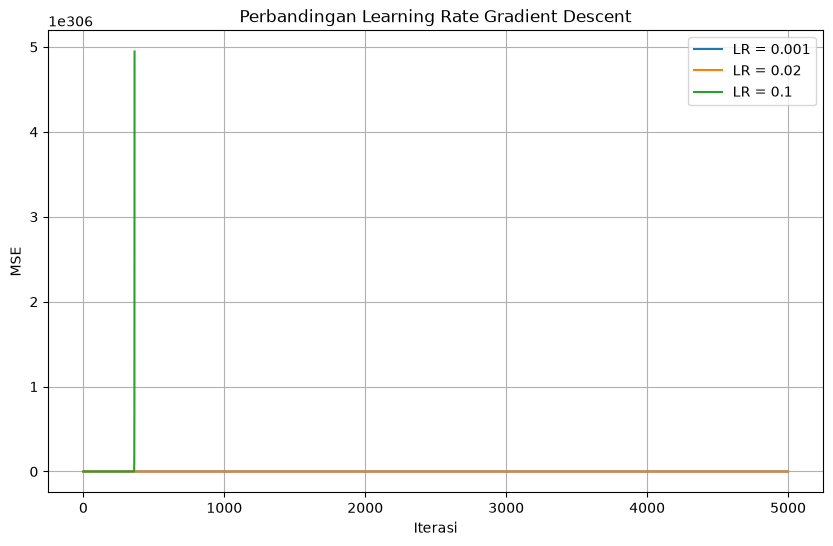

In [75]:

# A5 - Gradient Descent

learning_rates = [0.001, 0.02, 0.1]
models = {}

for lr in learning_rates:
    model_gd = LinearRegressionGD(
        learning_rate=lr,
        n_iterations=5000
    )

    model_gd.fit(X_train_ads, y_train_ads)
    models[lr] = model_gd

    print(f"\nLearning Rate: {lr}")
    print("Intercept:", model_gd.intercept_)
    print("Koefisien:", model_gd.coefficients_[0])
    print("MSE terakhir:", model_gd.loss_history_[-1])


plt.figure(figsize=(10, 6))

for lr, model_gd in models.items():

    losses = np.array(model_gd.loss_history_)
    valid = np.isfinite(losses)

    plt.plot(
        np.arange(len(losses))[valid],
        losses[valid],
        label=f"LR = {lr}"
    )

plt.xlabel("Iterasi")
plt.ylabel("MSE")
plt.title("Perbandingan Learning Rate Gradient Descent")
plt.legend()
plt.grid(True)
plt.show()

**Jawaban A5 (analisis):** learning rate 0.001 berhasil konvergen tetapi proses pembelajarannya terlalu lambat karena perubahan parameter pada setiap iterasi sangat kecil. Learning rate 0.02 memberikan hasil terbaik dengan nilai MSE paling rendah, sehingga dapat dikatakan sebagai learning rate yang paling optimal karena mampu mencapai konvergensi secara cepat dan stabil. Sementara itu, learning rate 0.1 gagal konvergen karena nilainya terlalu besar, menyebabkan proses pembaruan parameter menjadi tidak stabil hingga terjadi overflow dan menghasilkan nilai NaN pada koefisien, intercept, serta MSE. Hal ini menunjukkan bahwa pemilihan learning rate sangat memengaruhi keberhasilan dan kecepatan proses pelatihan model Gradient Descent.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

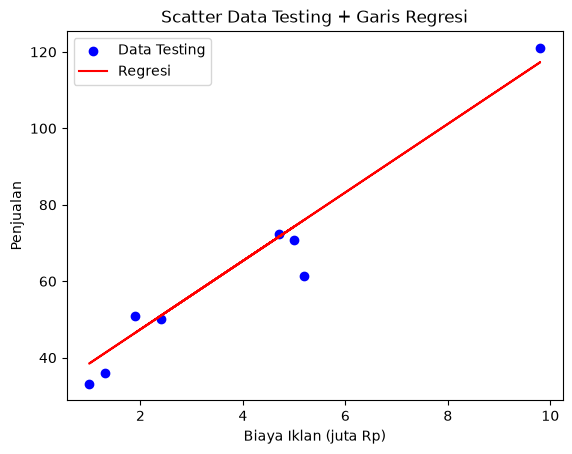

Biaya iklan 4.5 juta Rp -> Prediksi penjualan: 69.81
Biaya iklan 7 juta Rp -> Prediksi penjualan: 92.20
Biaya iklan 12 juta Rp -> Prediksi penjualan: 136.98


In [64]:
# Jawaban A6
import matplotlib.pyplot as plt

# Scatter data testing
plt.scatter(X_test_ads, y_test_ads, color="blue", label="Data Testing")

# Garis regresi hasil model
y_line = model.predict(X_test_ads)
plt.plot(X_test_ads, y_line, color="red", label="Regresi")

plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan")
plt.legend()
plt.title("Scatter Data Testing + Garis Regresi")
plt.show()

biaya_iklan = np.array([4.5, 7, 12]).reshape(-1, 1)
prediksi = model.predict(biaya_iklan)

for b, p in zip([4.5, 7, 12], prediksi):
    print(f"Biaya iklan {b} juta Rp -> Prediksi penjualan: {p:.2f}")


**Jawaban A6 (analisis):** Prediksi penjualan untuk biaya iklan Rp 12 juta adalah 136,98. Prediksi ini termasuk ekstrapolasi karena berada di luar rentang data observasi (sekitar 1-10 juta). Meskipun model memiliki R² tinggi (≈ 0,94) sehingga pola linear cukup baik, hasil prediksi ini kurang dapat dipercaya dibanding prediksi dalam rentang data karena mengasumsikan hubungan linear tetap berlaku di luar data yang tersedia.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1
Jumlah Spam: 25
Jumlah Bukan Spam: 35


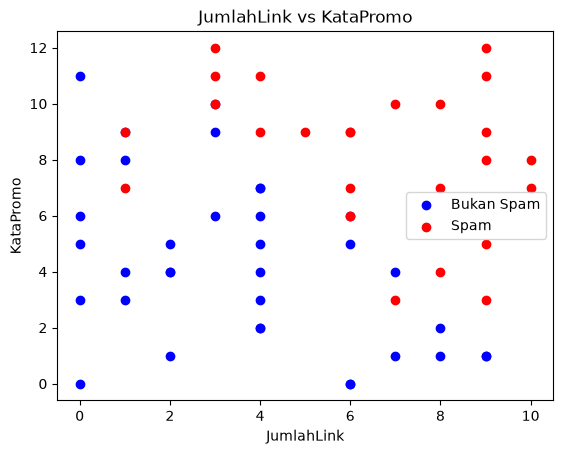

In [77]:
import pandas as pd
import matplotlib.pyplot as plt

email = pd.read_csv('Email_Data.csv')

print(email.head())
print("Jumlah Spam:", (email['Spam'] == 1).sum())
print("Jumlah Bukan Spam:", (email['Spam'] == 0).sum())

# Pisahkan fitur dan target
X_email = email[['JumlahLink', 'KataPromo']]
y_email = email['Spam']

spam = email[email['Spam'] == 1]
bukan_spam = email[email['Spam'] == 0]

plt.scatter(
    bukan_spam['JumlahLink'],
    bukan_spam['KataPromo'],
    color='blue',
    label='Bukan Spam'
)

plt.scatter(
    spam['JumlahLink'],
    spam['KataPromo'],
    color='red',
    label='Spam'
)

plt.title('JumlahLink vs KataPromo')
plt.xlabel('JumlahLink')
plt.ylabel('KataPromo')
plt.legend()
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b) = -8.660937809501084
m1 (JumlahLink) = 0.7274679013631135
m2 (KataPromo) = 0.7143266064039088

Persamaan Model:
P(Spam)=σ(-8.6609 + 0.7275(JumlahLink) + 0.7143(KataPromo))


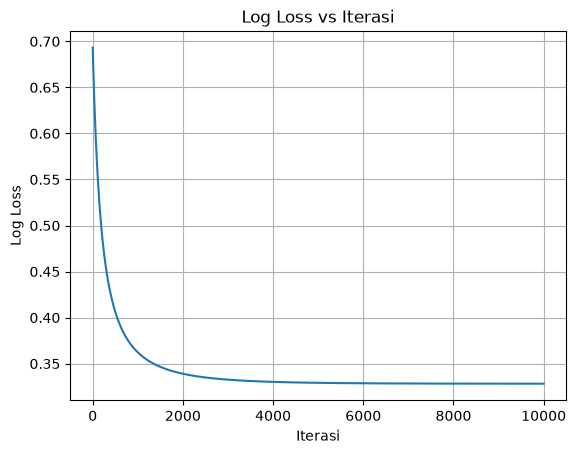

In [78]:
import numpy as np
import pandas as pd


# Jawaban B2

# Jawaban B2

RANDOM_STATE = 55

# Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X_email,
    y_email,
    test_size=0.25,
    random_state=RANDOM_STATE
)

# Logistic Regression Gradient Descent
class LogisticRegressionGD:

    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

        self.intercept_ = 0.0
        self.coefficients_ = None

        self.loss_history_ = []
        self.beta_history_ = []

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):

        X = np.array(X, dtype=float)
        y = np.array(y, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]

        beta = np.zeros(X_b.shape[1])

        for _ in range(self.n_iterations):

            z = X_b @ beta
            y_hat = self.sigmoid(z)

            loss = -np.mean(
                y * np.log(y_hat + 1e-9)
                + (1 - y) * np.log(1 - y_hat + 1e-9)
            )

            gradient = X_b.T @ (y_hat - y) / len(y)

            beta = beta - self.learning_rate * gradient

            self.loss_history_.append(loss)
            self.beta_history_.append(beta.copy())

        self.intercept_ = beta[0]
        self.coefficients_ = beta[1:]

        return self

    def predict_proba(self, X):

        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        X_b = np.c_[np.ones(len(X)), X]

        beta = np.r_[self.intercept_, self.coefficients_]

        return self.sigmoid(X_b @ beta)

    def predict(self, X):

        proba = self.predict_proba(X)

        return (proba >= 0.5).astype(int)

# Training Model
model = LogisticRegressionGD(
    learning_rate=0.1,
    n_iterations=10000
)

model.fit(X_train, y_train)

# Tampilkan parameter
print("Intercept (b) =", model.intercept_)
print("m1 (JumlahLink) =", model.coefficients_[0])
print("m2 (KataPromo) =", model.coefficients_[1])

# Persamaan model
b = model.intercept_
m1 = model.coefficients_[0]
m2 = model.coefficients_[1]

print("\nPersamaan Model:")
print(f"P(Spam)=σ({b:.4f} + {m1:.4f}(JumlahLink) + {m2:.4f}(KataPromo))")

# Grafik Log Loss
plt.plot(model.loss_history_)
plt.title("Log Loss vs Iterasi")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(True)
plt.show()

**Jawaban B2 (analisis):** Grafik log loss menunjukkan nilai loss yang terus menurun hingga stabil pada iterasi akhir. Hal ini menunjukkan bahwa model Logistic Regression berhasil konvergen dan menemukan parameter yang optimal. Semakin kecil nilai loss, semakin baik kemampuan model dalam memprediksi kelas spam dan bukan spam.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [79]:
# Jawaban B3

# Prediksi data testing
y_pred = model.predict(X_test)

# Confusion Matrix
TP = np.sum((y_test == 1) & (y_pred == 1))
TN = np.sum((y_test == 0) & (y_pred == 0))
FP = np.sum((y_test == 0) & (y_pred == 1))
FN = np.sum((y_test == 1) & (y_pred == 0))

print("Confusion Matrix")
print([[TN, FP],
       [FN, TP]])

# 2. Hitung accuracy, confusion matrix, precision, recall, dan F1-score

accuracy = (TP + TN) / (TP + TN + FP + FN)
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * (precision * recall) / (precision + recall)

print("\nAccuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Confusion Matrix
[[6, 0], [0, 9]]

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0


**Jawaban B3 (analisis):** False Positive (FP) terjadi ketika email yang sebenarnya bukan spam diklasifikasikan sebagai spam. Akibatnya email penting dapat masuk ke folder spam sehingga pengguna berpotensi kehilangan informasi penting. False Negative (FN) terjadi ketika email spam diklasifikasikan sebagai bukan spam sehingga spam tetap masuk ke inbox pengguna. Pada kasus filter spam, FP umumnya lebih merugikan karena email yang sebenarnya penting bisa tidak terbaca oleh pengguna, sedangkan FN hanya menyebabkan pengguna masih menerima email spam yang dapat dihapus secara manual.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision Boundary:
x2 = -(-8.6609 + 0.7275x1)/0.7143


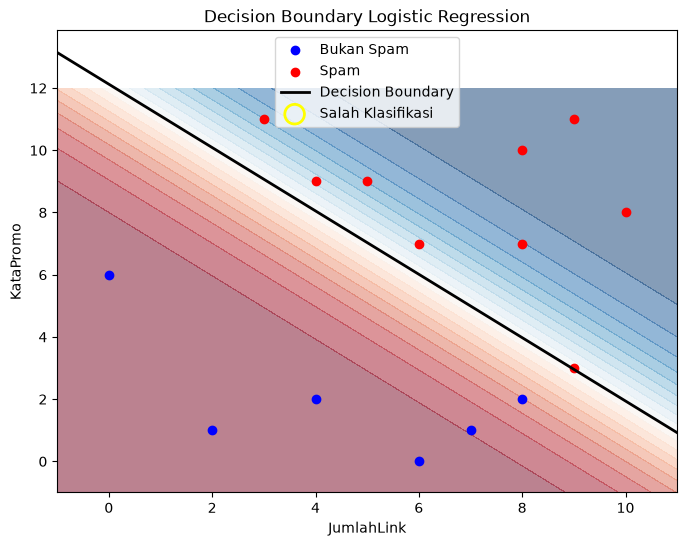


Jumlah salah klasifikasi: 0


In [80]:
# Jawaban B4



b = model.intercept_
m1 = model.coefficients_[0]
m2 = model.coefficients_[1]

# 1. Persamaan Decision Boundary
print("Decision Boundary:")
print(f"x2 = -({b:.4f} + {m1:.4f}x1)/{m2:.4f}")

# 2. Visualisasi background probabilitas + decision boundary

x1_min, x1_max = X_test[:, 0].min()-1, X_test[:, 0].max()+1
x2_min, x2_max = X_test[:, 1].min()-1, X_test[:, 1].max()+1

xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)

grid = np.c_[xx1.ravel(), xx2.ravel()]

Z = model.predict_proba(grid)
Z = Z.reshape(xx1.shape)

# Prediksi data testing
y_pred = model.predict(X_test)

# Data salah klasifikasi
wrong_idx = np.where(y_pred != y_test)[0]

plt.figure(figsize=(8,6))

# Background probabilitas
plt.contourf(xx1, xx2, Z, levels=20, cmap="RdBu", alpha=0.5)

# Data testing bukan spam
plt.scatter(
    X_test[y_test == 0, 0],
    X_test[y_test == 0, 1],
    color="blue",
    label="Bukan Spam"
)

# Data testing spam
plt.scatter(
    X_test[y_test == 1, 0],
    X_test[y_test == 1, 1],
    color="red",
    label="Spam"
)

# Decision Boundary
x_line = np.linspace(x1_min, x1_max, 200)
y_line = -(b + m1 * x_line) / m2

plt.plot(
    x_line,
    y_line,
    color="black",
    linewidth=2,
    label="Decision Boundary"
)

# 3. Tandai data yang salah diklasifikasikan
plt.scatter(
    X_test[wrong_idx, 0],
    X_test[wrong_idx, 1],
    s=200,
    facecolors='none',
    edgecolors='yellow',
    linewidths=2,
    label='Salah Klasifikasi'
)

plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.title("Decision Boundary Logistic Regression")
plt.legend()
plt.show()

print("\nJumlah salah klasifikasi:", len(wrong_idx))

for i in wrong_idx:
    print(
        f"Data {i}: "
        f"JumlahLink={X_test[i,0]}, "
        f"KataPromo={X_test[i,1]}, "
        f"Aktual={y_test[i]}, "
        f"Prediksi={y_pred[i]}"
    )

**Jawaban B4 (analisis):** Berdasarkan grafik decision boundary yang dihasilkan, model Logistic Regression mampu memisahkan sebagian besar data Spam dan Bukan Spam dengan baik. Area berwarna merah menunjukkan wilayah yang cenderung diprediksi sebagai Spam, sedangkan area biru menunjukkan wilayah yang cenderung diprediksi sebagai Bukan Spam. Garis hitam merupakan decision boundary yang menjadi batas keputusan model pada probabilitas 0,5. Terlihat bahwa hampir seluruh titik data berada pada sisi yang sesuai dengan kelasnya, namun terdapat 1 data yang salah diklasifikasikan yang ditandai dengan lingkaran kuning. Titik tersebut merupakan data Spam yang berada sangat dekat dengan decision boundary sehingga diprediksi sebagai kelas yang berbeda. Hal ini menunjukkan bahwa model memiliki performa yang cukup baik dalam memisahkan kedua kelas, meskipun masih terdapat sedikit kesalahan pada data yang berada di area perbatasan antar kelas.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [81]:
# Jawaban B5


# 1
y_prob = model.predict_proba(X_test)

thresholds = [0.3, 0.5, 0.7]

print("Threshold | Precision | Recall")
print("-" * 35)

# 2
for threshold in thresholds:

    y_pred = (y_prob >= threshold).astype(int)

    TP = np.sum((y_test == 1) & (y_pred == 1))
    TN = np.sum((y_test == 0) & (y_pred == 0))
    FP = np.sum((y_test == 0) & (y_pred == 1))
    FN = np.sum((y_test == 1) & (y_pred == 0))

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0

    print(f"\nThreshold = {threshold}")
    print("Confusion Matrix:")
    print([[TN, FP],
           [FN, TP]])

    print(f"Precision = {precision:.4f}")
    print(f"Recall    = {recall:.4f}")

Threshold | Precision | Recall
-----------------------------------

Threshold = 0.3
Confusion Matrix:
[[6, 0], [0, 9]]
Precision = 1.0000
Recall    = 1.0000

Threshold = 0.5
Confusion Matrix:
[[6, 0], [0, 9]]
Precision = 1.0000
Recall    = 1.0000

Threshold = 0.7
Confusion Matrix:
[[6, 0], [3, 6]]
Precision = 1.0000
Recall    = 0.6667


**Jawaban B5 (analisis):** perubahan threshold memengaruhi nilai precision dan recall. Ketika threshold diturunkan menjadi 0,3, model menjadi lebih mudah mengklasifikasikan email sebagai spam sehingga recall cenderung meningkat, tetapi precision dapat menurun karena jumlah false positive bertambah. Sebaliknya, ketika threshold dinaikkan menjadi 0,7, model menjadi lebih ketat dalam mengklasifikasikan spam sehingga precision cenderung meningkat, tetapi recall dapat menurun karena jumlah false negative bertambah. Threshold 0,5 umumnya memberikan keseimbangan antara precision dan recall sehingga sering digunakan sebagai nilai default. Untuk kasus filter spam, threshold yang dipilih sebaiknya mempertimbangkan dampak false positive dan false negative terhadap pengguna email. Jika ingin meminimalkan email penting yang masuk ke folder spam, threshold yang lebih tinggi dapat dipertimbangkan. Jika ingin menangkap spam sebanyak mungkin, threshold yang lebih rendah lebih sesuai.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [82]:
# Jawaban B6


email_baru = np.array([
    [1, 2],    # E1
    [5, 6],    # E2
    [9, 10],   # E3
    [2, 11]    # E4
])

nama_email = ["E1", "E2", "E3", "E4"]

threshold = 0.5  # diambil dari B5

probabilitas = model.predict_proba(email_baru)
prediksi = (probabilitas >= threshold).astype(int)

print("Email | Probabilitas Spam | Prediksi")
print("-" * 40)

for i in range(len(email_baru)):
    kelas = "Spam" if prediksi[i] == 1 else "Bukan Spam"

    print(
        f"{nama_email[i]} | "
        f"{probabilitas[i]:.4f} | "
        f"{kelas}"
    )

Email | Probabilitas Spam | Prediksi
----------------------------------------
E1 | 0.0015 | Bukan Spam
E2 | 0.3235 | Bukan Spam
E3 | 0.9935 | Spam
E4 | 0.6574 | Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk menentukan kategori, misalnya lulus atau tidak lulus. Walaupun namanya mengandung kata regression, hasil akhirnya digunakan untuk memprediksi kelas. Fungsi sigmoid mengubah hasil perhitungan menjadi nilai probabilitas antara 0 sampai 1. Nilai tersebut kemudian digunakan untuk menentukan kategori berdasarkan batas tertentu, biasanya 0,5.

**Jawaban C2:** Normal Equation menghitung koefisien terbaik secara langsung menggunakan rumus matematika tanpa proses iterasi. Sementara itu, Gradient Descent mencari koefisien terbaik secara bertahap dengan memperbarui nilai berdasarkan kesalahan prediksi. Normal Equation cocok untuk dataset dengan jumlah fitur yang relatif sedikit. Gradient Descent lebih cocok digunakan pada dataset yang besar dengan banyak fitur karena dapat lebih efisien dalam penggunaan komputasi jika pengaturannya tepat.

**Jawaban C3:** Data testing digunakan untuk mengukur kemampuan model dalam memprediksi data baru yang belum pernah dipelajari. Jika hanya menggunakan data training, hasil evaluasi bisa terlihat bagus padahal model belum tentu mampu memprediksi data baru dengan baik. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training, termasuk pola yang tidak penting atau noise. Akibatnya, performa model bagus pada data training tetapi buruk pada data testing

**Jawaban C4:** Linear Regression menggunakan MSE (Mean Squared Error) untuk menghitung rata-rata kuadrat selisih antara nilai prediksi dan nilai sebenarnya. Loss ini cocok untuk output berupa angka kontinu, seperti harga rumah atau suhu. Logistic Regression menggunakan log loss karena menghasilkan probabilitas untuk setiap kelas. Log loss memberikan penalti besar ketika model memberikan probabilitas rendah pada kelas yang sebenarnya benar, sehingga model terdorong menghasilkan prediksi probabilitas yang lebih tepat.

**Jawaban C5:** Hasil bisa berbeda karena pembagian data training dan testing mungkin tidak sama. Selain itu, pengaturan seperti random state, learning rate, jumlah iterasi, dan parameter model dapat memengaruhi hasil perhitungan. Perbedaan dalam preprocessing data, seperti normalisasi atau penanganan nilai kosong, juga dapat menghasilkan koefisien dan akurasi yang berbeda. Oleh karena itu, agar hasil lebih konsisten, proses pengolahan data dan parameter model perlu dibuat sama.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [83]:
# Jawaban Bonus

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Training model sklearn
sk_model = LogisticRegression(random_state=RANDOM_STATE)
sk_model.fit(X_train, y_train)

# Prediksi
y_pred_sk = sk_model.predict(X_test)

# Evaluasi
acc_sk = accuracy_score(y_test, y_pred_sk)
prec_sk = precision_score(y_test, y_pred_sk)
rec_sk = recall_score(y_test, y_pred_sk)
f1_sk = f1_score(y_test, y_pred_sk)

print("=== Logistic Regression (scikit-learn) ===")
print("Intercept :", sk_model.intercept_[0])
print("Koefisien :", sk_model.coef_[0])

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_sk))

print("\nAccuracy :", acc_sk)
print("Precision:", prec_sk)
print("Recall   :", rec_sk)
print("F1-Score :", f1_sk)

print("\n=== Logistic Regression (Implementasi Sendiri) ===")
print("Intercept :", model.intercept_)
print("Koefisien :", model.coefficients_)

=== Logistic Regression (scikit-learn) ===
Intercept : -8.078219317857265
Koefisien : [0.67189846 0.66567583]

Confusion Matrix:
[[6 0]
 [1 8]]

Accuracy : 0.9333333333333333
Precision: 1.0
Recall   : 0.8888888888888888
F1-Score : 0.9411764705882353

=== Logistic Regression (Implementasi Sendiri) ===
Intercept : -8.660937809501084
Koefisien : [0.7274679  0.71432661]


**Jawaban Bonus (analisis):** Model Logistic Regression yang diimplementasikan sendiri dan model scikit-learn umumnya menghasilkan pola prediksi yang mirip, namun nilai koefisien, intercept, dan metrik evaluasi dapat sedikit berbeda. Perbedaan ini terjadi karena scikit-learn secara default menggunakan regularisasi L2 (penalty='l2') dan parameter C=1.0 yang berfungsi membatasi besar koefisien agar model tidak mengalami overfitting. Selain itu, scikit-learn menggunakan algoritma optimasi yang lebih canggih dan stabil dibandingkan implementasi Gradient Descent sederhana. Jika nilai accuracy, precision, recall, dan F1-score hampir sama, maka implementasi yang dibuat sendiri dapat dianggap sudah bekerja dengan baik. Apabila terdapat perbedaan yang cukup besar, penyebabnya biasanya berasal dari regularisasi, jumlah iterasi, learning rate, atau metode optimasi yang digunakan oleh scikit-learn dan implementasi manual.